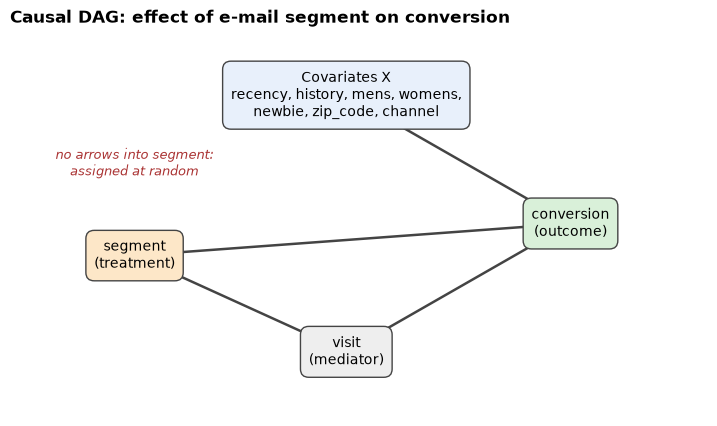

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import statsmodels.api as sm
from dowhy import CausalModel

df=pd.read_csv('../Data/Processed/Hillstorm_prepocessed.csv')

d = df.copy()
d["history_log"] = np.log(d["history"])
d = pd.concat([d, pd.get_dummies(d[["zip_code", "channel"]], drop_first=True, dtype=int)], axis=1)
COVARIATES = ["recency", "history_log", "history_floor", "mens", "womens", "newbie",
              "zip_code_Suburban", "zip_code_Urban", "channel_Phone", "channel_Web"]


G = nx.DiGraph([("segment", "visit"), ("visit", "conversion"), ("segment", "conversion"), ("X", "conversion")])
pos = {"X": (1.7, 1.5), "segment": (0, 0), "visit": (1.7, -0.9), "conversion": (3.5, 0.3)}
labels = {"X": "Covariates X\nrecency, history, mens, womens,\nnewbie, zip_code, channel",
          "segment": "segment\n(treatment)", "visit": "visit\n(mediator)", "conversion": "conversion\n(outcome)"}
colors = {"X": "#e8f0fb", "segment": "#fde7c8", "visit": "#eeeeee", "conversion": "#d9f0d9"}

fig, ax = plt.subplots(figsize=(9, 5))
boxes = {n: ax.text(x, y, labels[n], ha="center", va="center", fontsize=10, zorder=3,
                    bbox=dict(boxstyle="round,pad=0.6", fc=colors[n], ec="#444")) for n, (x, y) in pos.items()}
for a, b in G.edges:
    ax.annotate("", xy=pos[b], xytext=pos[a], zorder=2,
                arrowprops=dict(arrowstyle="-|>", mutation_scale=22, lw=1.8, color="#444", shrinkA=0, shrinkB=0,
                                patchA=boxes[a].get_bbox_patch(), patchB=boxes[b].get_bbox_patch()))
ax.text(0, 0.75, "no arrows into segment:\nassigned at random", ha="center", fontsize=9, color="#a33", style="italic")
ax.set_xlim(-1, 4.6); ax.set_ylim(-1.5, 2.1); ax.axis("off")
ax.set_title("Causal DAG: effect of e-mail segment on conversion", loc="left", fontweight="bold")
os.makedirs("../Reports/figures", exist_ok=True)
plt.savefig("../Reports/figures/dag.png", dpi=140, bbox_inches="tight")
plt.show()

In [ ]:
TREATMENT = "email_received"           
CONTROL = "No E-Mail"
ARMS = ["Mens E-Mail", "Womens E-Mail"]

train=pd.read_csv('../Data/Processed/train.csv')
dw = train.copy()
dw["history_log"] = np.log(dw["history"])
dw = pd.concat([dw, pd.get_dummies(dw[["zip_code", "channel"]], drop_first=True, dtype=int)], axis=1)
COVARIATES = ["recency", "history_log", "history_floor", "mens", "womens", "newbie",
              "zip_code_Suburban", "zip_code_Urban", "channel_Phone", "channel_Web"]

def make_gml(outcome, covariates):
    """e-mail -> every stage up to the outcome; earlier stages -> later stages; covariates -> outcome."""
    chain = STAGES[: STAGES.index(outcome) + 1]
    nodes = [TREATMENT] + chain + covariates
    edges = [(TREATMENT, s) for s in chain]
    edges += [(a, b) for i, a in enumerate(chain) for b in chain[i + 1:]]
    edges += [(c, outcome) for c in covariates]
    return ("graph [directed 1 "
            + " ".join(f'node [id "{n}" label "{n}"]' for n in nodes) + " "
            + " ".join(f'edge [source "{a}" target "{b}"]' for a, b in edges) + "]")

def identify(arm, outcome):
    chain = STAGES[: STAGES.index(outcome) + 1]
    sub = dw[dw["segment"].isin([CONTROL, arm])].copy()
    sub[TREATMENT] = (sub["segment"] == arm).astype(int)
    sub = sub[[TREATMENT] + chain + COVARIATES]
    model = CausalModel(data=sub, treatment=TREATMENT, outcome=outcome, graph=make_gml(outcome, COVARIATES))
    estimand = model.identify_effect(proceed_when_unidentifiable=True)
    return sub, estimand

rows, estimands = [], {}
for arm in ARMS:
    for outcome in STAGES:
        sub, estimand = identify(arm, outcome)
        adjust = estimand.get_backdoor_variables()
        rows.append({"Email arm": arm, "Outcome": outcome, "Training pair rows": len(sub),
                     "Backdoor adjustment": ", ".join(adjust) if adjust else "None required under randomized DAG"})
        estimands[(arm, outcome)] = estimand

table = pd.DataFrame(rows)
display(table)
print("\nExample DoWhy estimand:")
print(estimands[("Mens E-Mail", "visit")])

,Email arm,Outcome,Training pair rows,Backdoor adjustment
0,Mens E-Mail,visit,34091,None required under randomized DAG
1,Mens E-Mail,conversion,34091,None required under randomized DAG
2,Mens E-Mail,spend,34091,None required under randomized DAG
3,Womens E-Mail,visit,34154,None required under randomized DAG
4,Womens E-Mail,conversion,34154,None required under randomized DAG
5,Womens E-Mail,spend,34154,None required under randomized DAG



Example DoWhy estimand:
Estimand type: nonparametric-ate

### Estimand : 1
Estimand name: backdoor
Estimand expression:
        d                  
─────────────────(E[visit])
d[email_received]          
Estimand assumption 1, Unconfoundedness: If U→{email_received} and U→visit then P(visit|email_received,,U) = P(visit|email_received,)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

